# Equity return predictability

This notebook tests whether information available at month-end predicts future market excess returns for pension-fund and other long-horizon asset-allocation managers. It reproduces the CFM301 Chapter 8 table at 1-quarter, 1-year, 2-year, and 5-year horizons using local submitted data only.

The market series is CRSP value-weighted total return (`vwretd`), not `vwretx`. Future returns overlap at longer horizons, so t-statistics use Newey-West/HAC covariance with `horizon - 1` lags.

In [19]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import sys, scipy, matplotlib, statsmodels
print(f'Python {sys.version.split()[0]} | pandas {pd.__version__} | numpy {np.__version__} | '
      f'statsmodels {statsmodels.__version__} | scipy {scipy.__version__} | matplotlib {matplotlib.__version__}')

pd.set_option('display.max_columns', 100)
pd.set_option('display.float_format', lambda value: f'{value:,.4f}')
DATA_DIR = Path('Predictor Data')
START_DATE = '1926-01-31'

def read_series(filename, value_column, date_column='observation_date'):
    frame = pd.read_csv(DATA_DIR / filename, parse_dates=[date_column])
    frame['date'] = frame[date_column].dt.to_period('M').dt.to_timestamp('M')
    return frame[['date', value_column]].drop_duplicates('date').set_index('date').sort_index()

market = pd.read_csv(DATA_DIR / 'market_data_full_history_2025.csv', parse_dates=['date'])
market['date'] = market['date'].dt.to_period('M').dt.to_timestamp('M')
market = market.drop_duplicates('date').set_index('date').sort_index()
crsp = pd.read_csv(DATA_DIR / 'Market_Dividends_Returns.csv', parse_dates=['caldt'])
crsp['date'] = crsp['caldt'].dt.to_period('M').dt.to_timestamp('M')
crsp = crsp.drop_duplicates('date').set_index('date').sort_index()
data = market[['dividend_yield (annual)', 'earnings_yield (annual)']].rename(columns={'dividend_yield (annual)': 'dividend_yield', 'earnings_yield (annual)': 'earnings_yield'})
data = data.join(crsp[['vwretd']].rename(columns={'vwretd': 'market_total_return'}), how='outer')

files = {
    'AAA': ('AAA.csv', 'AAA'), 'BAA': ('BAA.csv', 'BAA'),
    'CPI': ('CPIAUCSL.csv', 'CPIAUCSL'), 'oil': ('DCOILWTICO (1).csv', 'DCOILWTICO'),
    'GDP': ('GDPC1.csv', 'GDPC1'), 'GS10': ('GS10.csv', 'GS10'),
    'INDPRO': ('INDPRO.csv', 'INDPRO'), 'TB3MS': ('TB3MS.csv', 'TB3MS'),
    'UNRATE': ('UNRATE.csv', 'UNRATE'), 'VIX': ('VIXCLS.csv', 'VIXCLS')
}
for name, (filename, column) in files.items():
    data = data.join(read_series(filename, column).rename(columns={column: name}), how='outer')

cay = pd.read_csv(DATA_DIR / 'cay_current.csv', parse_dates=['date'])
cay['date'] = cay['date'].dt.to_period('M').dt.to_timestamp('M')
cay = cay.drop_duplicates('date').set_index('date')['cay=c-0.218 a-0.801y+0.441'].rename('cay')
data = data.join(cay, how='outer').sort_index().loc[pd.Timestamp(START_DATE):]

# TB3MS is an annualized percent rate; convert it to an effective monthly rate.
data['rf_monthly'] = (1 + data['TB3MS'] / 100) ** (1 / 12) - 1
data['market_excess'] = (1 + data['market_total_return']) / (1 + data['rf_monthly']) - 1
data.head()

Python 3.11.4 | pandas 2.0.3 | numpy 1.24.3 | statsmodels 0.14.0 | scipy 1.10.0 | matplotlib 3.7.1


,dividend_yield,earnings_yield,market_total_return,AAA,BAA,CPI,oil,GDP,GS10,INDPRO,TB3MS,UNRATE,VIX,cay,rf_monthly,market_excess
date,,,,,,,,,,,,,,,,
1926-01-31,0.0482,0.0988,0.0006,4.8200,6.0900,NaN,NaN,NaN,NaN,6.4357,NaN,NaN,NaN,NaN,NaN,NaN
1926-02-28,0.0489,0.0987,-0.0330,4.7700,6.0200,NaN,NaN,NaN,NaN,6.4357,NaN,NaN,NaN,NaN,NaN,NaN
1926-03-31,0.0525,0.1058,-0.0640,4.7900,6.0500,NaN,NaN,NaN,NaN,6.5165,NaN,NaN,NaN,NaN,NaN,NaN
1926-04-30,0.0549,0.1089,0.0370,4.7400,5.9800,NaN,NaN,NaN,NaN,6.5165,NaN,NaN,NaN,NaN,NaN,NaN
1926-05-31,0.0554,0.1081,0.0121,4.7100,5.8600,NaN,NaN,NaN,NaN,6.4626,NaN,NaN,NaN,NaN,NaN,NaN


## Predictor construction and cleaning

All sources are converted to month-end dates and duplicate dates are removed before joining. The quarterly `cay` series is carried forward from the last observed quarter-end. Predictors are winsorized at the 1st and 99th percentiles within each usable estimation sample; returns are not winsorized.

In [20]:
predictors = pd.DataFrame(index=data.index)
predictors['Dividend yield'] = data['dividend_yield']
predictors['Earnings yield'] = data['earnings_yield']
predictors['Term spread (10y - 3m)'] = data['GS10'] - data['TB3MS']
predictors['Credit spread (BAA - AAA)'] = data['BAA'] - data['AAA']
predictors['Unemployment rate'] = data['UNRATE']
predictors['GDP growth (past year)'] = data['GDP'].ffill().pct_change(12, fill_method=None)
predictors['Industrial production (past year)'] = data['INDPRO'].pct_change(12, fill_method=None)
predictors['Past 1-year return'] = (1 + data['market_total_return']).rolling(12, min_periods=12).apply(np.prod, raw=True) - 1
predictors['Past volatility (last quarter)'] = data['market_total_return'].rolling(3, min_periods=3).std(ddof=1) * np.sqrt(12)
predictors['Inflation (past year)'] = data['CPI'].pct_change(12, fill_method=None)
predictors['Oil price (past-year change)'] = data['oil'].pct_change(12, fill_method=None)
predictors['Risk-free rate'] = data['TB3MS'] / 100
predictors['VIX'] = data['VIX']
predictors['Consumption-wealth ratio (cay)'] = data['cay'].ffill()
returns = data['market_excess'].rename('future_excess_return')
missing_before = predictors.isna().sum().rename('missing_values')
print(f'Analysis dates: {data.index.min():%Y-%m} to {data.index.max():%Y-%m}')
print(f'Duplicate month-end observations removed: {int(data.index.duplicated().sum())}')
display(missing_before.to_frame().sort_values('missing_values', ascending=False))

Analysis dates: 1926-01 to 2026-10
Duplicate month-end observations removed: 0


,missing_values
Oil price (past-year change),860
VIX,815
Term spread (10y - 3m),328
Consumption-wealth ratio (cay),314
Unemployment rate,266
Inflation (past year),266
GDP growth (past year),264
Risk-free rate,97
Past 1-year return,33
Past volatility (last quarter),24


In [21]:
HORIZONS = {'1 quarter': 3, '1 year': 12, '2 years': 24, '5 years': 60}

def future_compounded_return(monthly_returns, horizon):
    return (1 + monthly_returns).rolling(horizon, min_periods=horizon).apply(np.prod, raw=True).shift(-horizon) - 1

def winsorize(series):
    lower, upper = series.quantile([0.01, 0.99])
    return series.clip(lower=lower, upper=upper), int((series < lower).sum() + (series > upper).sum())

def predictability_row(predictor, horizon):
    sample = pd.concat([predictor.rename('x'), future_compounded_return(returns, horizon).rename('y')], axis=1).dropna()
    sample['x'], winsorized = winsorize(sample['x'])
    model = sm.OLS(sample['y'], sm.add_constant(sample['x']))
    fitted = model.fit(cov_type='HAC', cov_kwds={'maxlags': horizon - 1, 'use_correction': True})
    return sample['x'].corr(sample['y']), fitted.tvalues['x'], len(sample), winsorized

rows = []
for predictor_name in predictors.columns:
    row = {'Predictor': predictor_name}
    for horizon_name, horizon in HORIZONS.items():
        correlation, t_stat, observations, winsorized = predictability_row(predictors[predictor_name], horizon)
        row[f'{horizon_name} correlation'] = correlation
        row[f'{horizon_name} t-stat'] = t_stat
        row[f'{horizon_name} N'] = observations
        row[f'{horizon_name} winsorized'] = winsorized
    rows.append(row)

results = pd.DataFrame(rows).set_index('Predictor')
table = pd.DataFrame(index=results.index)
for horizon_name in HORIZONS:
    table[horizon_name] = results[f'{horizon_name} correlation'].map(lambda value: f'{value:.2f}') + ' (' + results[f'{horizon_name} t-stat'].map(lambda value: f'{value:.2f}') + ')'
display(table.style.set_caption('Correlation with future excess return; HAC t-statistic in parentheses'))

,1 quarter,1 year,2 years,5 years
Predictor,,,,
Dividend yield,0.11 (2.40),0.25 (3.06),0.34 (3.28),0.53 (3.87)
Earnings yield,0.09 (2.03),0.21 (2.69),0.27 (2.64),0.42 (2.31)
Term spread (10y - 3m),0.08 (1.63),0.17 (2.06),0.21 (2.45),0.38 (3.15)
Credit spread (BAA - AAA),0.07 (1.08),0.14 (1.62),0.13 (1.05),0.09 (0.65)
Unemployment rate,0.15 (3.28),0.22 (2.78),0.14 (1.34),0.22 (1.26)
GDP growth (past year),-0.12 (-2.20),-0.25 (-2.86),-0.19 (-2.08),-0.19 (-1.49)
Industrial production (past year),-0.10 (-1.73),-0.16 (-1.72),-0.05 (-0.47),-0.00 (-0.04)
Past 1-year return,-0.04 (-0.66),-0.16 (-2.23),-0.24 (-3.88),-0.20 (-2.35)
Past volatility (last quarter),0.12 (2.48),0.06 (1.41),0.06 (1.01),0.05 (0.65)


This is the required slide-comparable table. Each cell reports the correlation between the predictor observed at time `t` and the compounded future **market excess return**. The HAC t-statistic uses `horizon - 1` lags to account for overlapping holding-period returns. Positive valuation correlations support the dividend-discount-model prediction that cheap markets have higher subsequent returns.

,1 quarter N,1 quarter clipped at 1%/99%,1 year N,1 year clipped at 1%/99%,2 years N,2 years clipped at 1%/99%,5 years N,5 years clipped at 1%/99%
Predictor,,,,,,,,
Dividend yield,1090,22,1081,22,1069,22,1033,22
Earnings yield,1090,22,1081,22,1069,22,1033,22
Term spread (10y - 3m),858,18,849,18,837,18,801,16
Credit spread (BAA - AAA),1090,22,1081,22,1069,22,1033,22
Unemployment rate,921,18,912,18,900,18,864,16
GDP growth (past year),921,18,912,18,900,18,864,18
Industrial production (past year),1090,22,1081,22,1069,22,1033,22
Past 1-year return,1090,22,1081,22,1069,22,1033,22
Past volatility (last quarter),1090,22,1081,22,1069,22,1033,22


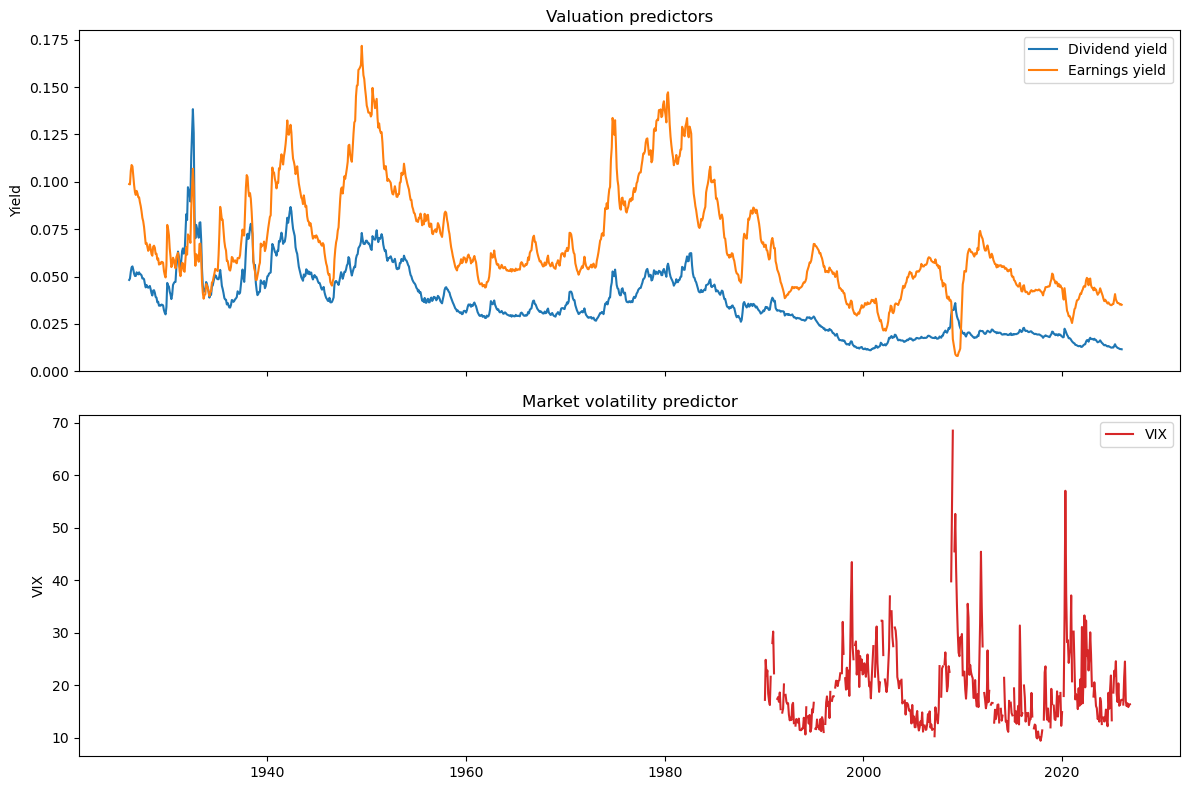

In [22]:
audit_columns = [column for horizon_name in HORIZONS for column in (f'{horizon_name} N', f'{horizon_name} winsorized')]
display(results[audit_columns].rename(columns=lambda value: value.replace(' winsorized', ' clipped at 1%/99%')))

fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
axes[0].plot(data.index, data['dividend_yield'], label='Dividend yield')
axes[0].plot(data.index, data['earnings_yield'], label='Earnings yield')
axes[0].set_ylabel('Yield')
axes[0].set_title('Valuation predictors')
axes[0].legend()
axes[1].plot(data.index, data['VIX'], color='tab:red', label='VIX')
axes[1].set_ylabel('VIX')
axes[1].set_title('Market volatility predictor')
axes[1].legend()
fig.tight_layout()
plt.show()

## Comparison with the slide table (requirement 8)

The table below sets the slides' values (Ch. 8, slides 28, 32 and 34; US, about 1926–2011) next to our baseline estimates (1926–2024) for every predictor and horizon. Each cell shows **correlation (t-stat)**. **Bold = |t| > 2** (significant). The last two columns count significant horizons in each version and flag sign changes. The table is also saved as `slides_vs_project.csv`.

In [23]:
SLIDE_VALUES = {  # (correlation, t-stat) for 1 quarter, 1 year, 2 years, 5 years
    'Dividend yield':                    [(0.12, 1.12), (0.23, 1.25), (0.33, 1.48), (0.49, 1.95)],
    'Earnings yield':                    [(0.18, 2.23), (0.33, 2.55), (0.41, 2.79), (0.48, 2.31)],
    'VIX':                               [(0.12, 0.96), (0.10, 0.63), (0.13, 0.75), (-0.16, -0.47)],
    'Past volatility (last quarter)':    [(0.05, 0.55), (0.09, 0.65), (0.13, 0.78), (0.06, 0.17)],
    'Consumption-wealth ratio (cay)':    [(0.16, 2.92), (0.30, 2.62), (0.42, 2.23), (0.53, 1.34)],
    'Term spread (10y - 3m)':            [(0.11, 1.60), (0.23, 1.84), (0.27, 1.66), (0.35, 1.61)],
    'Credit spread (BAA - AAA)':         [(0.02, 0.15), (0.08, 0.34), (0.12, 0.44), (0.20, 0.67)],
    'Unemployment rate':                 [(0.12, 1.86), (0.22, 1.85), (0.19, 1.08), (0.22, 0.75)],
    'GDP growth (past year)':            [(0.01, 0.17), (-0.13, -1.37), (-0.11, -1.25), (-0.08, -0.84)],
    'Industrial production (past year)': [(-0.01, -0.06), (-0.04, -0.25), (0.02, 0.08), (-0.04, -0.20)],
    'Past 1-year return':                [(-0.01, -0.12), (-0.05, -0.26), (-0.13, -0.55), (-0.26, -1.39)],
    'Inflation (past year)':             [(-0.07, -1.07), (-0.12, -0.94), (-0.10, -0.58), (-0.03, -0.09)],
    'Oil price (past-year change)':      [(-0.10, -1.20), (-0.18, -1.20), (-0.16, -1.08), (-0.11, -0.78)],
    'Risk-free rate':                    [(-0.07, -1.23), (-0.12, -1.17), (-0.15, -1.05), (-0.22, -0.97)],
}
GROUPS = {'Dividend yield': 'Valuation ratios', 'Earnings yield': 'Valuation ratios',
          'VIX': 'Risk & risk aversion', 'Past volatility (last quarter)': 'Risk & risk aversion',
          'Consumption-wealth ratio (cay)': 'Risk & risk aversion'}
horizon_names = list(HORIZONS)

rows, sig_mask = [], []
for name, slide_vals in SLIDE_VALUES.items():
    ours = [(results.loc[name, f'{h} correlation'], results.loc[name, f'{h} t-stat']) for h in horizon_names]
    row, mask = {}, {}
    for h, (sc, st), (oc, ot) in zip(horizon_names, slide_vals, ours):
        row[(h, 'Slides')] = f'{sc:.2f} ({st:.2f})'
        row[(h, 'Ours')] = f'{oc:.2f} ({ot:.2f})'
        mask[(h, 'Slides')], mask[(h, 'Ours')] = abs(st) > 2, abs(ot) > 2
    n_slide = sum(abs(t) > 2 for _, t in slide_vals)
    n_ours = sum(abs(t) > 2 for _, t in ours)
    flips = sum(np.sign(a) != np.sign(b) and abs(a) > 0.02 and abs(b) > 0.02
                for (a, _), (b, _) in zip(slide_vals, ours))
    row[('Summary', 'Sig. horizons')] = f'{n_slide} → {n_ours}'
    row[('Summary', 'Sign flips')] = flips if flips else ''
    mask[('Summary', 'Sig. horizons')] = mask[('Summary', 'Sign flips')] = False
    rows.append(row)
    sig_mask.append(mask)

group_index = pd.MultiIndex.from_tuples(
    [(GROUPS.get(n, 'Business cycle & markets'), n) for n in SLIDE_VALUES], names=['Group', 'Predictor'])
comparison_table = pd.DataFrame(rows, index=group_index)
comparison_table.columns = pd.MultiIndex.from_tuples(comparison_table.columns)
sig_frame = pd.DataFrame(sig_mask, index=group_index)
sig_frame.columns = comparison_table.columns
comparison_table.to_csv('slides_vs_project.csv')

def highlight(_):
    return pd.DataFrame(np.where(sig_frame.to_numpy(dtype=bool), 'font-weight: bold; color: #0d47a1', ''),
                        index=sig_frame.index, columns=sig_frame.columns)

first_ret, last_ret = returns.first_valid_index().year, returns.last_valid_index().year
styled = (comparison_table.style
          .apply(highlight, axis=None)
          .set_caption(f'Correlation (t-stat) with future excess returns: slides (~1926–2011) vs. ours ({first_ret}–{last_ret}). '
                       'Bold = |t| > 2.')
          .set_table_styles([
              {'selector': 'th.col_heading.level0', 'props': 'text-align: center; border-bottom: 1px solid #999;'},
              {'selector': 'td', 'props': 'text-align: center; padding: 4px 10px;'},
              {'selector': 'caption', 'props': 'caption-side: top; font-weight: bold; text-align: left;'},
          ]))
display(styled)

### What the comparison shows

**1. The correlations replicate.** Signs match the slides almost everywhere. The only real flip is VIX at 5 years (−0.16 on the slides vs. +0.13 here; neither significant); the other differences in sign are cells where the slide value is about zero. Most correlations are within about 0.1 of the slide values. The largest gaps are *cay* (up to −0.20) and the earnings yield (−0.06 to −0.14). For example, the dividend yield is 0.12 / 0.23 / 0.33 / 0.49 on the slides vs. 0.11 / 0.25 / 0.34 / 0.53 here, and correlations still grow with the horizon. The economic picture is unchanged: cheap markets are followed by higher returns, and business-cycle variables mostly have the expected signs.

**2. Our t-stats are larger, so many more cells are significant.** On the slides only the earnings yield and *cay* are significant. In our baseline, 11 of 14 predictors are significant at one or more horizons. The correlations are similar, so the difference comes mainly from:
- **The overlap correction.** Newey-West with h−1 lags is less conservative than the correction the slides likely used (e.g. Hodrick standard errors), so it understates the noise from overlapping windows.
- **13 more years of data** (2012–2024) add observations.

The sensitivity analysis (section 12) supports the first explanation: with **non-overlapping returns**, most macro predictors lose significance (oil 4 → 0, inflation 4 → 1, past 1-year return 3 → 0), while the valuation ratios survive.

**3. Predictor by predictor:**
- **Dividend yield:** 0 → 4 significant horizons with nearly identical correlations. Post-2011 data strengthens it, and it is significant under every sensitivity assumption, so it is our most reliable result.
- **Earnings yield:** significant in both, but weaker here (0.42 vs. 0.48 at 5 years). It is strong before 1990 and insignificant after (section 12), which pulls the full-sample estimate down. Our version is trailing 12-month E/P, while the slides likely used Shiller's smoothed E/P10.
- ***cay*:** 3 significant horizons in both, but in different places: weaker at short horizons, significant at 5 years. The quarterly *cay* file ends in 2019, so check how it is carried forward before relying on this row.
- **Oil, inflation and GDP growth:** 0 → 3–4 significant horizons. Oil data starts only in 1986, and quarterly GDP needs a publication lag, so these are the least reliable changes.
- **VIX, credit spread and industrial production:** insignificant in both, consistent with the slides' conclusion that volatility alone does not predict returns.

**Summary:** Our extended-sample correlations closely match the slides in sign and size, confirming that valuation ratios predict long-horizon returns. Our larger t-stats mostly reflect the overlap correction rather than stronger predictability. Under non-overlapping returns, only the valuation ratios and a few macro variables remain significant. The dividend yield is the one predictor that becomes clearly significant once post-2011 data is added.

## Expected-return versus volatility predictability

The slides emphasize that volatility is more predictable than returns. This diagnostic compares the VIX at time `t` with annualized realized volatility over the following horizon; it is separate from the required return-predictability table.

In [24]:
def future_realized_volatility(monthly_returns, horizon):
    return monthly_returns.rolling(horizon, min_periods=horizon).std(ddof=1).shift(-horizon) * np.sqrt(12)

volatility_rows = []
for horizon_name, horizon in HORIZONS.items():
    sample = pd.concat([predictors['VIX'].rename('VIX'), future_realized_volatility(data['market_total_return'], horizon).rename('future_volatility')], axis=1).dropna()
    model = sm.OLS(sample['future_volatility'], sm.add_constant(sample['VIX']))
    fitted = model.fit(cov_type='HAC', cov_kwds={'maxlags': horizon - 1, 'use_correction': True})
    volatility_rows.append({'Horizon': horizon_name, 'Correlation': sample['VIX'].corr(sample['future_volatility']), 'HAC t-statistic': fitted.tvalues['VIX'], 'N': len(sample)})

volatility_table = pd.DataFrame(volatility_rows).set_index('Horizon')
display(volatility_table)
print('Convention: absolute HAC t-statistics of 2 or more are treated as statistically significant.')

,Correlation,HAC t-statistic,N
Horizon,,,
1 quarter,0.2911,4.8967,372
1 year,0.3787,4.1966,364
2 years,0.3021,3.1180,353
5 years,-0.1598,-1.0408,319


Convention: absolute HAC t-statistics of 2 or more are treated as statistically significant.


## 9. Interpretation using the dividend discount model

From class, `P = D / (E(r) - g)`, so rearranging gives `D/P = E(r) - g`. Holding expected dividend growth `g` approximately constant, a high dividend yield means investors require a higher expected return. The same logic applies to the earnings yield: a high `E/P` means the price is low relative to the earnings generated by the market, which is consistent with a higher required and expected future return. The extended table supports this prediction: dividend yield and earnings yield have positive correlations with future excess returns, and the correlations generally increase from one quarter to five years. Their post-2011 observations are included in the extended sample through the latest available market-return date.

Long-horizon predictability is stronger because valuation ratios move slowly while returns compound. A small difference in expected monthly returns accumulates over 12, 24, or 60 months, whereas one-quarter returns contain much more noise. The longer-horizon estimates should still be interpreted cautiously because overlapping observations reduce the effective sample size; the table therefore reports HAC t-statistics.

**What our numbers say.** The dividend yield's correlation with future excess returns rises from 0.11 (1 quarter) to 0.25 (1 year), 0.34 (2 years) and 0.53 (5 years), significant at every horizon. The earnings yield follows the same pattern (0.09 → 0.42). Both have the sign the dividend discount model predicts. Two qualifications:
- **The evidence after 1990 is mixed.** The dividend yield is still significant at 1, 2 and 5 years after 1990 and after 2011 (5-year correlation 0.69 in 1990–2024). The earnings yield is **not significant at any horizon after 1990** (5-year correlation 0.03). Post-2011 data therefore supports the model for dividends but not for earnings.
- **The effect is small at short horizons.** A 1-quarter correlation of 0.11 means the dividend yield explains only about 1% of next-quarter return variation (0.11² ≈ 0.012). Even at 5 years, where it explains about 28% (0.53²), overlapping windows overstate the precision.

**Why predictability is stronger at longer horizons.** Valuation ratios are very persistent: they drift slowly over years. Each month they shift expected returns by a small amount, which is swamped by month-to-month noise. Over 5 years, those small shifts add up while the noise partly cancels out. So the predictable share of returns grows with the horizon.

## 10. Five-bucket valuation analysis

Following slides 26–28, observations are sorted into five equal-count buckets by dividend yield at time `t`. Q1 is the lowest-yield (most expensive) group and Q5 is the highest-yield (cheapest) group. The plots show average compounded future returns and vertical ±2 standard-deviation bands, matching the slide presentation. These bands are dispersion bands, not confidence intervals.

,average_ratio,one_year_mean,one_year_sd,five_year_mean,five_year_sd,observations
bucket,,,,,,
Q1 lowest,1.70%,3.91%,13.03%,3.58%,4.86%,207
Q2,2.61%,4.51%,16.28%,7.10%,6.83%,206
Q3,3.38%,7.39%,15.58%,4.70%,5.46%,207
Q4,4.34%,9.15%,19.93%,6.73%,4.84%,206
Q5 highest,6.00%,16.79%,17.39%,13.27%,5.45%,207


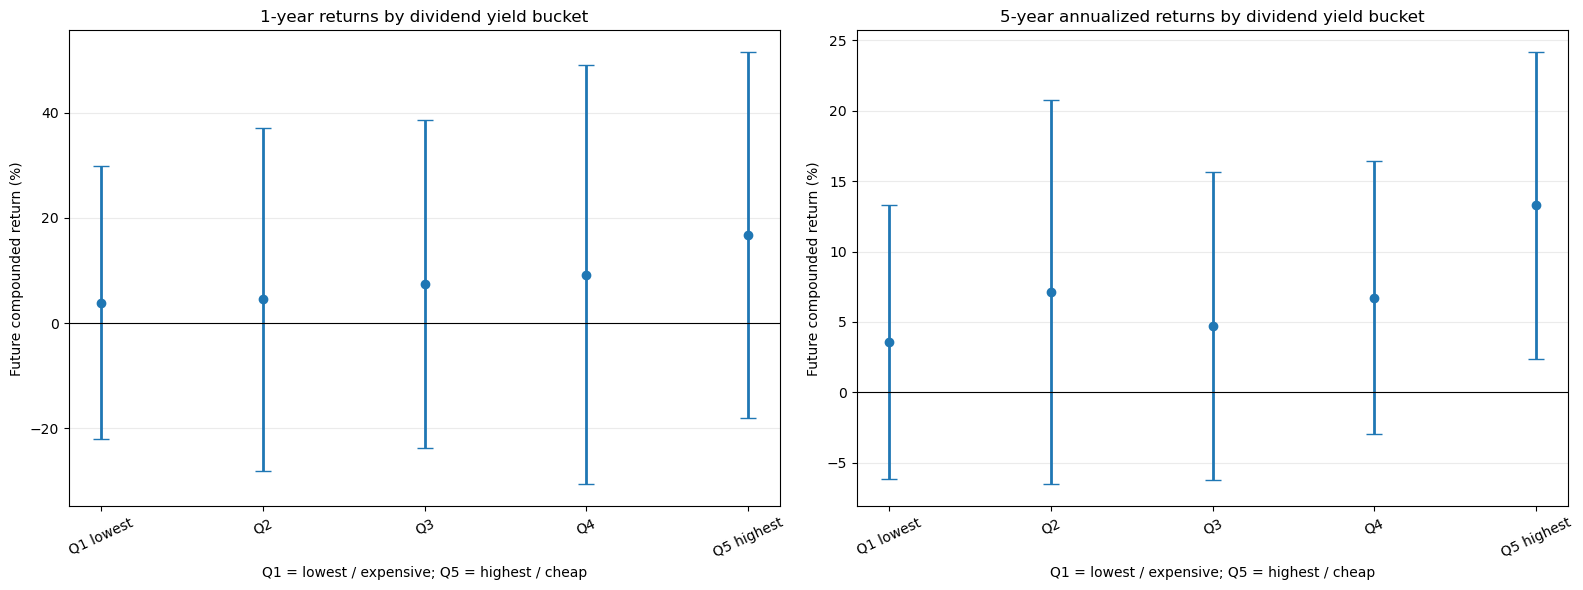

In [25]:
def bucket_analysis(ratio_name='Dividend yield'):
    ratio = predictors[ratio_name]
    bucket_data = pd.DataFrame({
        'ratio': ratio,
        'future_1_year': future_compounded_return(returns, 12),
        'future_5_year': (1 + future_compounded_return(returns, 60)) ** (1 / 5) - 1,
    }).dropna()
    bucket_data['bucket'] = pd.qcut(bucket_data['ratio'], 5, labels=['Q1 lowest', 'Q2', 'Q3', 'Q4', 'Q5 highest'])
    summary = bucket_data.groupby('bucket', observed=False).agg(
        average_ratio=('ratio', 'mean'),
        one_year_mean=('future_1_year', 'mean'), one_year_sd=('future_1_year', 'std'),
        five_year_mean=('future_5_year', 'mean'), five_year_sd=('future_5_year', 'std'),
        observations=('ratio', 'size'),
    )
    display(summary.style.format({
        'average_ratio': '{:.2%}', 'one_year_mean': '{:.2%}', 'one_year_sd': '{:.2%}',
        'five_year_mean': '{:.2%}', 'five_year_sd': '{:.2%}', 'observations': '{:.0f}'
    }).set_caption(f'{ratio_name} buckets: means and standard deviations'))

    labels = summary.index.astype(str)
    fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=False)
    for ax, mean_col, sd_col, title in [
        (axes[0], 'one_year_mean', 'one_year_sd', '1-year returns'),
        (axes[1], 'five_year_mean', 'five_year_sd', '5-year annualized returns'),
    ]:
        mean = summary[mean_col] * 100
        error = 2 * summary[sd_col] * 100
        ax.errorbar(labels, mean, yerr=error, fmt='o', capsize=6, linewidth=2)
        ax.axhline(0, color='black', linewidth=0.8)
        ax.set_title(f'{title} by {ratio_name.lower()} bucket')
        ax.set_ylabel('Future compounded return (%)')
        ax.set_xlabel('Q1 = lowest / expensive; Q5 = highest / cheap')
        ax.grid(axis='y', alpha=0.25)
        ax.tick_params(axis='x', rotation=25)
    fig.tight_layout()
    plt.show()
    return summary

dividend_bucket_summary = bucket_analysis('Dividend yield')

### Bucket analysis: what it shows

| Dividend-yield bucket | Avg. yield | Next 1 year: mean (±2 SD range) | Next 5 years, per year: mean (±2 SD range) |
|---|---|---|---|
| Q1, most expensive | 1.70% | 3.9% (−22% to +30%) | 3.6% (−6% to +13%) |
| Q2 | 2.61% | 4.5% (−28% to +37%) | 7.1% (−7% to +21%) |
| Q3 | 3.38% | 7.4% (−24% to +39%) | 4.7% (−6% to +16%) |
| Q4 | 4.34% | 9.2% (−31% to +49%) | 6.7% (−3% to +16%) |
| Q5, cheapest | 6.00% | 16.8% (−18% to +52%) | 13.3% (+2% to +24%) |

- **Valuation matters on average.** Average 1-year excess returns rise steadily from the most expensive fifth of months (3.9%) to the cheapest fifth (16.8%), a gap of about 13 percentage points a year. At 5 years the cheapest bucket earned 13.3% a year vs. 3.6% for the most expensive. The 5-year pattern is not perfectly monotonic (Q2 > Q3), which shows how noisy even long-horizon averages are.
- **But the noise is enormous.** At 1 year the ±2 SD ranges overlap almost completely: every bucket's range runs from about −20–30% to +30–50%. Buying when the market is cheap does **not** protect you from a bad year, and buying when it is expensive can still earn +30%.
- **Long horizons are more reliable.** The 5-year ranges are much narrower, and only the cheapest bucket has a range that stays above zero (+2% to +24% a year).

This confirms the class conclusion: **equity returns are predictable, but the predictability is weak.** Valuations are useful for setting long-run return expectations and nearly useless for calling next year's return.

## 11. Returns versus volatility: GARCH(1,1)

A GARCH(1,1) model estimates `h_t = omega + alpha * r_(t-1)^2 + beta * h_(t-1)`, where `h_t` is conditional monthly variance. The model is estimated by Gaussian quasi-maximum likelihood using monthly total returns. Its annualized conditional volatility is compared with ex-post realized volatility from the next three months. This is a volatility forecast comparison, not a claim that volatility forecasts expected returns.

,Estimate,Interpretation
omega,0.7153,Long-run variance scale
alpha,0.1229,ARCH response to new shocks
beta,0.8538,GARCH persistence


GARCH volatility / next-quarter realized-volatility correlation: 0.487


,count,mean,std,min,25%,50%,75%,max
GARCH annualized volatility,"1,186.0000",17.0949,7.2725,9.7753,13.1437,15.2684,18.0109,69.0187
next-quarter realized volatility,"1,186.0000",13.9165,10.9258,0.2864,7.1982,11.4568,16.9536,96.4000


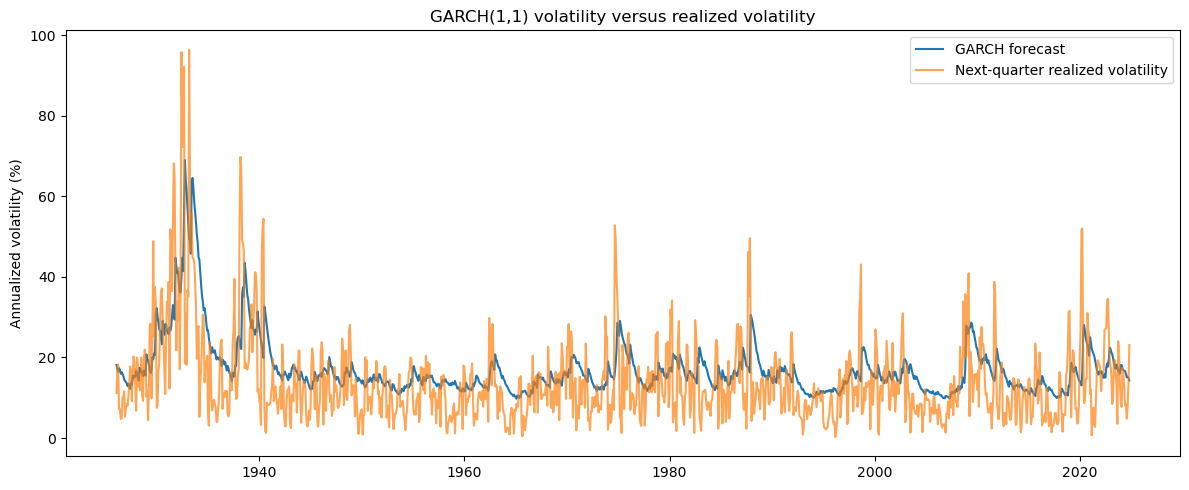

In [26]:
from scipy.optimize import minimize

garch_returns = data['market_total_return'].dropna() * 100

def garch_variance(parameters, values):
    omega, alpha, beta = parameters
    variance = np.empty(len(values))
    variance[0] = np.var(values)
    for i in range(1, len(values)):
        variance[i] = omega + alpha * values.iloc[i - 1] ** 2 + beta * variance[i - 1]
    return variance

def garch_objective(parameters, values):
    omega, alpha, beta = parameters
    if omega <= 0 or alpha < 0 or beta < 0 or alpha + beta >= 0.999:
        return 1e12
    variance = garch_variance(parameters, values)
    return 0.5 * np.sum(np.log(variance) + values.to_numpy() ** 2 / variance)

initial = [0.05 * garch_returns.var(), 0.08, 0.90]
fit = minimize(garch_objective, initial, args=(garch_returns,), method='Nelder-Mead', options={'maxiter': 10000, 'xatol': 1e-10})
if not fit.success:
    raise RuntimeError(f'GARCH estimation failed: {fit.message}')
garch_parameters = pd.Series(fit.x, index=['omega', 'alpha', 'beta'])
conditional_volatility = pd.Series(np.sqrt(garch_variance(fit.x, garch_returns)) * np.sqrt(12), index=garch_returns.index, name='GARCH annualized volatility')
realized_volatility = data['market_total_return'].rolling(3, min_periods=3).std(ddof=1).shift(-2) * np.sqrt(12) * 100
volatility_comparison = pd.concat([conditional_volatility, realized_volatility.rename('next-quarter realized volatility')], axis=1).dropna()
garch_summary = pd.DataFrame({
    'Estimate': garch_parameters,
    'Interpretation': ['Long-run variance scale', 'ARCH response to new shocks', 'GARCH persistence']
})
display(garch_summary)
print(f'GARCH volatility / next-quarter realized-volatility correlation: {volatility_comparison.iloc[:, 0].corr(volatility_comparison.iloc[:, 1]):.3f}')
display(volatility_comparison.describe().T)

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(volatility_comparison.index, volatility_comparison.iloc[:, 0], label='GARCH forecast')
ax.plot(volatility_comparison.index, volatility_comparison.iloc[:, 1], label='Next-quarter realized volatility', alpha=0.7)
ax.set_ylabel('Annualized volatility (%)')
ax.set_title('GARCH(1,1) volatility versus realized volatility')
ax.legend()
fig.tight_layout()
plt.show()

### GARCH: is volatility more predictable than returns?

- **Estimates:** α = 0.12 (reaction to new shocks) and β = 0.85 (persistence). α + β = 0.98 is close to 1, so a volatility shock fades only slowly. This is the same "volatility clustering" shown on the slides.
- **Forecast accuracy:** the GARCH forecast has a correlation of **0.49** with realized volatility over the next quarter. The VIX gives a similar result: its correlation with future realized volatility is 0.29 (1 quarter), 0.38 (1 year) and 0.30 (2 years), all significant (t = 3.1–4.9).
- **Compared with returns:** return predictors reach correlations of only about **0.2–0.35 at 1 year** (dividend yield 0.25, earnings yield 0.21; oil −0.34, but only from 1986), and about 0.1–0.2 at 1 quarter.

**Conclusion: volatility is clearly more predictable than expected returns**, as concluded in class. Our 0.49 is below the slides' 0.63, probably because our realized volatility uses only 3 monthly returns per quarter, which is a noisy measure. The slides likely used daily data. For investors, the practical lesson is that *risk* can be forecast well enough to adjust exposure (volatility timing), while *returns* cannot be forecast well enough to time the market.

## 12. Sensitivity analysis

The full predictability table is re-run with **one assumption changed at a time**. Everything else stays at the baseline.

| # | Assumption | Baseline | Alternatives |
|---|---|---|---|
| 1 | **Sample period** | 1926 to latest | 1926–1989, 1990–latest, 2012–latest (post-2011) |
| 2 | **Overlap correction** | Newey-West, `h − 1` lags | Newey-West with `2h` lags; **non-overlapping** returns (every *h*-th month, no overlap, so lag 0) |
| 3 | **Return definition** | CRSP `vwretd` minus T-bill (excess) | Nominal `vwretd`; equal-weighted `ewretd` (only if that column is in the CRSP file) |
| 4 | **Winsorization** | 1st/99th percentile | 5th/95th percentile; none |

In sub-periods, future returns are compounded only within the sub-period, so the 1926–1989 window never uses post-1989 returns.
The summary table counts, for each predictor and assumption, how many of the 4 horizons are significant (|t| > 2).


In [27]:
SIG = 2.0
BASE = dict(start=None, end=None, ret='excess', overlap='nw', lag_mult=None, winsor=(0.01, 0.99))

def winsorize_at(series, cut):
    if cut is None:
        return series, 0
    lower, upper = series.quantile([cut[0], cut[1]])
    return series.clip(lower=lower, upper=upper), int((series < lower).sum() + (series > upper).sum())

def pick_returns(kind):
    if kind == 'excess':
        return data['market_excess']
    if kind == 'nominal':
        return data['market_total_return']
    if kind == 'equal_weighted':
        ew = crsp['ewretd'].reindex(data.index)
        return (1 + ew) / (1 + data['rf_monthly']) - 1
    raise ValueError(kind)

def run_table(start=None, end=None, ret='excess', overlap='nw', lag_mult=None, winsor=(0.01, 0.99)):
    """Re-estimate corr and t for every predictor and horizon under one set of assumptions."""
    period_x = predictors.loc[start:end]
    period_r = pick_returns(ret).loc[start:end]
    out = []
    for name in predictors.columns:
        for horizon_name, h in HORIZONS.items():
            s = pd.concat([period_x[name].rename('x'),
                           future_compounded_return(period_r, h).rename('y')], axis=1).dropna()
            if overlap == 'non_overlapping':
                s = s.iloc[::h]                       # one observation per h months: no shared months
                lags = 0
            else:
                lags = h - 1 if lag_mult is None else int(lag_mult * h)
            if len(s) < 10:                           # too few observations to estimate
                out.append({'Predictor': name, 'Horizon': horizon_name, 'corr': np.nan, 't': np.nan, 'N': len(s)})
                continue
            s['x'], _ = winsorize_at(s['x'], winsor)
            fit = sm.OLS(s['y'], sm.add_constant(s['x'])).fit(
                cov_type='HAC', cov_kwds={'maxlags': lags, 'use_correction': True})
            out.append({'Predictor': name, 'Horizon': horizon_name,
                        'corr': s['x'].corr(s['y']), 't': fit.tvalues['x'], 'N': len(s)})
    return pd.DataFrame(out)

scenarios = {
    'Baseline':                      {},
    # 1. sample period
    '1926-1989':                     dict(end='1989-12-31'),
    '1990-latest':                   dict(start='1990-01-31'),
    '2012-latest (post-2011)':       dict(start='2012-01-31'),
    # 2. overlap correction
    'NW lags = 2h':                  dict(lag_mult=2),
    'Non-overlapping returns':       dict(overlap='non_overlapping'),
    # 3. return definition
    'Nominal returns':               dict(ret='nominal'),
    # 4. winsorization
    'Winsorize 5%/95%':              dict(winsor=(0.05, 0.95)),
    'No winsorization':              dict(winsor=None),
}
if 'ewretd' in crsp.columns:
    scenarios['Equal-weighted (excess)'] = dict(ret='equal_weighted')
else:
    print("Equal-weighted index skipped: add 'ewretd' to Market_Dividends_Returns.csv to include it.")

sens = {name: run_table(**{**BASE, **kw}) for name, kw in scenarios.items()}

# --- compact summary: number of horizons (out of 4) with |t| > 2 ---
summary = pd.DataFrame({name: tab.assign(sig=tab['t'].abs() > SIG).groupby('Predictor', sort=False)['sig'].sum()
                        for name, tab in sens.items()})
summary = summary.loc[predictors.columns].astype(int)
display(summary.style.background_gradient(cmap='Blues', vmin=0, vmax=4)
        .set_caption('Number of horizons (of 4) with |t| > 2, by assumption'))

# --- detail: corr (t) per predictor and horizon, for each assumption ---
def as_slide_table(tab):
    wide = tab.pivot(index='Predictor', columns='Horizon', values=['corr', 't'])
    cells = pd.DataFrame(index=predictors.columns)
    for horizon_name in HORIZONS:
        c, t = wide[('corr', horizon_name)], wide[('t', horizon_name)]
        cells[horizon_name] = [('' if pd.isna(a) else f'{a:.2f} ({b:.2f})') for a, b in zip(c.loc[cells.index], t.loc[cells.index])]
    return cells

sensitivity_detail = pd.concat({name: as_slide_table(tab) for name, tab in sens.items()}, names=['Assumption', 'Predictor'])
sensitivity_detail.to_csv('sensitivity_detail.csv')
summary.to_csv('sensitivity_summary.csv')

for name in scenarios:
    if name == 'Baseline':
        continue
    display(sensitivity_detail.loc[name].style.set_caption(f'{name}: correlation (t-stat)'))

# --- which predictors are robust? significant at >=1 horizon under EVERY assumption ---
robust = summary.index[(summary > 0).all(axis=1)].tolist()
fragile = summary.index[(summary['Baseline'] > 0) & ~(summary > 0).all(axis=1)].tolist()
print('Significant under every assumption:', robust or 'none')
print('Significant in the baseline but not under every assumption:', fragile or 'none')


Equal-weighted index skipped: add 'ewretd' to Market_Dividends_Returns.csv to include it.


,Baseline,1926-1989,1990-latest,2012-latest (post-2011),NW lags = 2h,Non-overlapping returns,Nominal returns,Winsorize 5%/95%,No winsorization
Dividend yield,4,4,3,3,4,3,3,4,4
Earnings yield,4,4,0,0,3,2,4,3,3
Term spread (10y - 3m),3,1,1,1,3,1,1,3,3
Credit spread (BAA - AAA),0,0,2,3,0,0,0,0,0
Unemployment rate,2,0,4,3,2,2,3,2,2
GDP growth (past year),3,2,2,4,2,1,2,3,3
Industrial production (past year),0,0,1,2,0,0,0,0,0
Past 1-year return,3,1,2,3,3,0,1,2,3
Past volatility (last quarter),1,1,0,1,1,0,0,0,1
Inflation (past year),4,0,2,2,4,1,0,3,4


,1 quarter,1 year,2 years,5 years
Predictor,,,,
Dividend yield,0.17 (2.86),0.37 (4.03),0.51 (4.92),0.78 (6.74)
Earnings yield,0.11 (2.17),0.28 (3.29),0.37 (2.95),0.60 (3.17)
Term spread (10y - 3m),0.19 (2.59),0.24 (1.96),0.13 (1.11),0.21 (1.67)
Credit spread (BAA - AAA),0.08 (1.15),0.12 (1.11),0.07 (0.45),0.01 (0.04)
Unemployment rate,0.13 (1.96),0.12 (1.01),-0.05 (-0.35),-0.00 (-0.02)
GDP growth (past year),-0.16 (-2.22),-0.29 (-2.53),-0.17 (-1.41),-0.07 (-0.58)
Industrial production (past year),-0.13 (-1.84),-0.18 (-1.66),-0.03 (-0.26),0.04 (0.29)
Past 1-year return,-0.03 (-0.47),-0.18 (-1.98),-0.25 (-3.18),-0.12 (-1.03)
Past volatility (last quarter),0.15 (2.27),0.02 (0.41),0.01 (0.09),0.01 (0.18)


,1 quarter,1 year,2 years,5 years
Predictor,,,,
Dividend yield,0.12 (1.50),0.31 (2.95),0.44 (2.54),0.69 (3.48)
Earnings yield,0.08 (0.83),0.11 (0.72),0.14 (0.64),0.03 (0.11)
Term spread (10y - 3m),-0.04 (-0.55),0.07 (0.71),0.27 (1.65),0.50 (3.22)
Credit spread (BAA - AAA),0.02 (0.14),0.21 (1.88),0.33 (2.87),0.40 (2.78)
Unemployment rate,0.19 (2.76),0.35 (3.65),0.39 (2.82),0.60 (3.90)
GDP growth (past year),-0.07 (-0.79),-0.21 (-1.68),-0.25 (-2.36),-0.50 (-3.54)
Industrial production (past year),-0.02 (-0.23),-0.14 (-0.94),-0.19 (-1.32),-0.34 (-2.22)
Past 1-year return,-0.04 (-0.42),-0.12 (-0.93),-0.23 (-2.01),-0.40 (-5.17)
Past volatility (last quarter),0.07 (0.91),0.14 (1.56),0.18 (1.58),0.14 (0.68)


,1 quarter,1 year,2 years,5 years
Predictor,,,,
Dividend yield,0.15 (1.51),0.39 (3.00),0.59 (5.96),0.69 (6.90)
Earnings yield,-0.06 (-0.54),-0.02 (-0.06),0.30 (1.41),0.29 (1.32)
Term spread (10y - 3m),-0.03 (-0.29),-0.11 (-0.73),-0.32 (-2.39),-0.08 (-0.42)
Credit spread (BAA - AAA),0.10 (1.12),0.47 (3.23),0.74 (7.55),0.46 (3.95)
Unemployment rate,0.31 (3.40),0.57 (5.42),0.31 (1.73),0.37 (2.93)
GDP growth (past year),-0.25 (-2.74),-0.61 (-5.09),-0.46 (-5.26),-0.62 (-7.10)
Industrial production (past year),-0.19 (-1.94),-0.54 (-3.92),-0.46 (-3.73),-0.19 (-0.84)
Past 1-year return,-0.14 (-1.40),-0.35 (-2.21),-0.58 (-7.86),-0.24 (-4.27)
Past volatility (last quarter),0.18 (1.83),0.21 (1.05),0.24 (2.16),0.00 (0.13)


...

,1 quarter,1 year,2 years,5 years
Predictor,,,,
Dividend yield,0.11 (1.98),0.26 (2.84),0.38 (2.80),0.54 (3.04)
Earnings yield,0.09 (1.66),0.21 (2.33),0.31 (2.17),0.22 (0.83)
Term spread (10y - 3m),0.08 (1.21),0.09 (0.86),0.28 (1.61),0.55 (2.04)
Credit spread (BAA - AAA),0.08 (1.09),0.15 (1.50),0.13 (0.91),0.25 (1.18)
Unemployment rate,0.16 (2.85),0.21 (2.35),0.18 (1.45),0.13 (0.51)
GDP growth (past year),-0.09 (-1.44),-0.28 (-2.49),-0.30 (-1.91),-0.43 (-1.73)
Industrial production (past year),-0.10 (-1.34),-0.19 (-1.53),-0.09 (-0.50),-0.36 (-1.49)
Past 1-year return,-0.06 (-0.90),-0.14 (-1.31),-0.13 (-0.79),-0.34 (-1.35)
Past volatility (last quarter),0.12 (1.62),0.12 (1.31),0.08 (0.58),0.28 (1.26)


,1 quarter,1 year,2 years,5 years
Predictor,,,,
Dividend yield,0.10 (1.47),0.22 (2.42),0.32 (3.56),0.46 (4.44)
Earnings yield,0.13 (3.30),0.26 (4.22),0.36 (4.98),0.49 (5.49)
Term spread (10y - 3m),0.05 (1.04),0.12 (1.44),0.15 (1.57),0.31 (2.28)
Credit spread (BAA - AAA),0.07 (0.66),0.12 (1.03),0.13 (1.41),0.18 (1.48)
Unemployment rate,0.17 (3.57),0.25 (3.18),0.19 (1.98),0.35 (2.15)
GDP growth (past year),-0.12 (-2.11),-0.24 (-2.74),-0.15 (-1.72),-0.14 (-1.38)
Industrial production (past year),-0.05 (-0.77),-0.11 (-0.96),-0.04 (-0.33),-0.10 (-0.88)
Past 1-year return,0.01 (0.11),-0.08 (-0.73),-0.16 (-1.79),-0.25 (-3.40)
Past volatility (last quarter),0.04 (0.54),-0.01 (-0.12),-0.01 (-0.12),0.05 (0.70)


,1 quarter,1 year,2 years,5 years
Predictor,,,,
Dividend yield,0.11 (2.35),0.24 (2.94),0.34 (3.13),0.52 (3.70)
Earnings yield,0.09 (1.99),0.20 (2.60),0.27 (2.67),0.42 (2.34)
Term spread (10y - 3m),0.08 (1.58),0.17 (2.09),0.20 (2.27),0.39 (3.18)
Credit spread (BAA - AAA),0.05 (0.88),0.12 (1.27),0.10 (0.80),0.07 (0.46)
Unemployment rate,0.15 (3.15),0.22 (2.86),0.16 (1.52),0.23 (1.38)
GDP growth (past year),-0.12 (-2.28),-0.25 (-3.04),-0.19 (-2.07),-0.21 (-1.93)
Industrial production (past year),-0.09 (-1.69),-0.17 (-1.99),-0.06 (-0.62),-0.01 (-0.06)
Past 1-year return,-0.02 (-0.37),-0.15 (-1.94),-0.24 (-3.65),-0.19 (-2.08)
Past volatility (last quarter),0.09 (1.90),0.05 (1.12),0.06 (0.92),0.03 (0.45)


,1 quarter,1 year,2 years,5 years
Predictor,,,,
Dividend yield,0.11 (2.40),0.25 (3.12),0.35 (3.34),0.53 (3.92)
Earnings yield,0.09 (1.92),0.20 (2.63),0.27 (2.58),0.41 (2.27)
Term spread (10y - 3m),0.09 (1.65),0.18 (2.10),0.21 (2.51),0.38 (3.09)
Credit spread (BAA - AAA),0.07 (1.11),0.15 (1.67),0.13 (1.11),0.10 (0.69)
Unemployment rate,0.16 (3.45),0.23 (2.88),0.14 (1.33),0.22 (1.23)
GDP growth (past year),-0.12 (-2.14),-0.25 (-2.80),-0.19 (-2.09),-0.17 (-1.19)
Industrial production (past year),-0.11 (-1.83),-0.15 (-1.72),-0.04 (-0.42),-0.01 (-0.04)
Past 1-year return,-0.05 (-0.85),-0.17 (-2.32),-0.24 (-3.70),-0.20 (-2.43)
Past volatility (last quarter),0.14 (2.60),0.07 (1.55),0.06 (1.05),0.05 (0.73)


Significant under every assumption: ['Dividend yield', 'Term spread (10y - 3m)', 'GDP growth (past year)']
Significant in the baseline but not under every assumption: ['Earnings yield', 'Unemployment rate', 'Past 1-year return', 'Past volatility (last quarter)', 'Inflation (past year)', 'Oil price (past-year change)', 'Risk-free rate', 'Consumption-wealth ratio (cay)']


### Sensitivity analysis: conclusions

The summary table above counts how many of the 4 horizons are significant under each assumption.

- **Dividend yield: robust.** Significant at 3–4 horizons under **every** assumption: all three sub-periods, both overlap corrections, nominal returns and both winsorization choices. It is the only valuation ratio that survives everywhere.
- **Earnings yield and *cay*: depend on the era.** Both are significant at all 4 horizons in 1926–1989. After 1990, the earnings yield has 0 significant horizons and *cay* has 0 (1 after 2011).
- **Macro and market variables: depend on the overlap correction.** Oil, inflation, GDP growth, past 1-year return and the term spread are mostly significant in the baseline, but most drop to 0–1 significant horizons with **non-overlapping returns** (oil 4 → 0, inflation 4 → 1, past 1-year return 3 → 0). Their baseline significance is partly an artifact of overlapping windows.
- **VIX, past volatility, industrial production and credit spread: rarely or never significant.**
- **Winsorization barely matters.** Results with 5/95 cut-offs or none are almost identical to the 1/99 baseline. Doubling the Newey-West lags also changes little.

**Effect on the economic question:** the conclusion does not change, but it narrows. Only the dividend yield gives a predictability signal that holds across periods and methods, and even it explains a small share of short-horizon returns. Most other predictors are too fragile to base an allocation decision on.

## 13. Conclusion

**Question:** should a long-horizon investor, such as a pension fund setting its strategic asset allocation, adjust its equity exposure based on valuation and other predictors, and is return predictability still present after 2011?

**Answer:**
1. **Yes, predictability is still there, mainly through valuations.** Extending the sample to 2024 reproduces the slides' correlations closely in sign and size. The dividend yield becomes significant at every horizon and stays significant after 1990 and after 2011.
2. **But it is weak and noisy.** The dividend yield explains only about 1% of next-quarter returns. In the bucket analysis, cheap and expensive markets have overlapping ±2 SD ranges at 1 year. The earnings yield and *cay* stopped working after 1990, and most macro predictors lose significance once overlapping observations are handled strictly.
3. **Volatility is far more predictable than returns** (GARCH correlation 0.49 vs. about 0.2–0.35 at best for 1-year return predictors).

**Recommendation for the audience:** pension fund managers should use valuation ratios, especially the dividend yield, to **set long-run return expectations** and to make **modest, slow-moving tilts** in strategic equity allocation. They should **not** use these predictors for short-term market timing: the signal is too weak relative to the noise at horizons under a few years. Adjusting exposure to **forecast volatility** is better supported by the data than adjusting it to forecast returns.

**Limitations:**
- **Sample start:** excess returns use the 3-month T-bill (TB3MS), which starts in 1934, so the baseline effectively covers 1934–2024, not 1926–2024.
- **Data:** *cay* ends in 2019 and is carried forward; the VIX starts in 1990 and oil data in 1986; quarterly GDP is not lagged for its publication date.
- **Past volatility and GARCH realized volatility** use monthly rather than daily returns.
- **Overlap:** with overlapping long-horizon returns, Newey-West t-stats are likely too large. The non-overlapping results in section 12 are the more conservative guide.